#### Question 0 (0 points)

Include your code in a (well-documented, commented, clear) assignment01.ipynb file.
Scores for the code-based questions below will be based on your written responses and
code

#### Question 1 (20 points)

There are a lot of ways to store network data. Each format generally has advantages
and disadvantages that make them suited to particular types of situations. Let’s
explore the differences between storing network data in a .csv, pickle, or .gml file,
and in Elasticsearch, which is commonly used for graph database applications.

_For your research, look at the documentation for each approach, seek out StackOverflow
threads, and consider consulting the Bagrow & Ahn textbook._



(a) What are the advantages of each storage approach?

1. .csv according to https://stackoverflow.com/questions/48770542/what-is-the-difference-between-save-a-pandas-dataframe-to-pickle-and-to-csv, has the advantage of being human readable and cross platform
2. pickle according to https://stackoverflow.com/questions/48770542/what-is-the-difference-between-save-a-pandas-dataframe-to-pickle-and-to-csv has the advantage of fast saving and loading and being more space efficient (for disk saves) than csv. It also saves the exact representation of the dataframe per how the pandas library sees it, thereby reducing the risk of lost data when converting to csv and back, and can store any binary subject.
3. .gml, according to Gephi (https://docs.gephi.org/desktop/User_Manual/Import/GML_File_Format/) has the advantage of being a plain text file format with a simple, human-readable syntax used to represent graphs. Storing all nodes, edges and attributes into a single file
4. Elastisearch (https://stackoverflow.com/questions/57328151/how-does-elasticsearch-store-data) is a vector database solution. It stores data via "lucene" a text search engine, that saves data in a custom binary format. It has the advantage of being highly optimized. It also can handle any kind of data: structured, unstructured and vectors, and allows for search engine, analytics engine, geospatial engine and inference service queries on your dataset.

(b) What are the disadvantages of each storage approach?
1. .csv according to the textbook can be subject to data loss due to the conversion process. In particular, delimiter collisions where part of the data contains the delimiter innately (e.g., "," in a "Surname, First Name") used to separate entries. In addition, .csv is less space efficient than other formats.
2. pickle according to https://stackoverflow.com/questions/48770542/what-is-the-difference-between-save-a-pandas-dataframe-to-pickle-and-to-csv has the disadvantage of not being as universal and cross-platform as other formats, it may require you to be using the same Python version to save between computers for instance, and is generally not binary stable. It also can introduce potential security vulnerabilities should you be downloading an unknown file in this format that was corrupted or contains malicious code,
3. .gml according to the textbook has the disadvantage of using a non-standard format. It also is not fully supported by Gephi according to their documentation (particularly for some data structures _though it's not specified which_). It also has the disadvantage of being similarly named to GraphML and Geography Markup Language (also GML).
4. Elastisearch, according to GeeksForGeeks (https://www.geeksforgeeks.org/elasticsearch/advantages-and-disadvantages-of-elasticsearch/) has the disadvantage of being very complex to setup and maintain as an industry grade database solution. It also is resource intensive requiring sufficient CPU, memory and storage. It also prioritizes performance and scale over consistency and reliability, meaning that there are scenarios where data is not 100% reliable across the database machines. It also requires expertise and has a steep learning curve to pick-up.

(c) At least one of these storage approaches poses a non-trivial security risk. Which
one(s) should we worry about, and what is the security risk? Please explain this
as simply as possible.

.pkl (pickle) may have a security problem according to the official python documentation.
The exact warning can be found here https://docs.python.org/3/library/pickle.html as:

"_Warning: The pickle module is not secure. Only unpickle data you trust._

_It is possible to construct malicious pickle data which will execute arbitrary code during unpickling. Never unpickle data that could have come from an untrusted source, or that could have been tampered with._

_Consider signing data with hmac if you need to ensure that it has not been tampered with._

_Safer serialization formats such as json may be more appropriate if you are processing untrusted data. See Comparison with json._"

What this means is that when loading in a .pkl file, should that file secretly contain code, Python may execute that code rather than simply load it as a plain data-frame. As such, if the code is malicious, you could unwittingly introduce hackers or malware to your pc.

(d) For each storage approach, think of a scenario where that storage approach would
be an optimal choice. Explain your reasoning.

1. .csv can be good when you are working with simple data that you know for certain would not contain potential collisions (e.g., data that is all integers perhaps). It would also be optimal in a scenario when you need to share data widely to many different machines and programs.
2. pickle can be optimal when you are working with your own data and need a fast and reliable way to store it. If you create the file and do not share it to potential bad actors, you can avoid the security risk related to this format, and thereby take advantage of its reliability, speed and spatial efficiency.
3. .gml can be optimal when you don't need to share the data very widely but need some of the benefits of .csv (e.g., human-readable) and, cannot store it as such due to delimiter collisions. .gml provides a similar human-readable benefit with the tradeoff of less universality.
4. Elastisearch, can be optimal when you truly need a long-term industry-grade solution for a large dataset, and want the performance, scalability and unique analytics engine capabilities that can come from this.

#### Question 2 (20 points).

_Algorithm 11.1 in Bagrow & Ahn_, the basic edge exchange algorithm, modifies a graph
in place to produce a null model while preserving the degree distribution. It does so
by picking two edges at random and swapping their endpoints.


* 1: procedure EDGE EXCHANGE(G, t)
* 2: s ← 0
* 3: while s < t do
* 4: (i, j) ← get random edge(G)
* 2
* 5: (u, v) ← get random edge(G)
* 6: if i = u or i = v or j = u or j = v then
* 7: continue
* 8: end if
* 9: if has edge(G, i, v) or has edge(G, j, u) then
* 10: continue
* 11: end if
* 12: remove edge(G, i, j)
* 13: remove edge(G, u, v)
* 14: add edge(G, i, v)
* 15: add edge(G, j, u)
* 16: s ← s + 1
* 17: end while
* 18: return G
* 19: end procedure


(a) (Bagrow & Ahn Question 11.2) The basic edge exchange algorithm (as shown
above) will enter an infinite loop and never end if no allowable exchanges are
present. Describe a scenario where you will never be able to find an allowable
edge exchange according to this algorithm.

One simple edge-case scenario when you will never be able to find an allowable edge exchange according to this algorithm is, if you're dataset is too small. For instance, in theory, if you had a graph with just 1 edge between 2 nodes, this algorithm may never find a pair to exchange,

(b) (Bagrow & Ahn Question 11.3) Modify the algorithm to prevent an infinite loop
by abandoning the exchange process after reaching a given number of attempts
without a successful exchange.

* 1: procedure EDGE EXCHANGE(G, t)
#Hard time-out when we have missed a total number of times equal to the sum of all edges in the graph.
* **1b:  hard_limit = get_total_number_of_edges(G)**
* 2: s ← 0
* 3: while s < t and hard_limit > 0 do
* 4: (i, j) ← get random edge(G)
* 5: (u, v) ← get random edge(G)
* 6: if i = u or i = v or j = u or j = v then
* 6b:   **hard_limit -=1**
* 7:    continue
* 8: end if
* 9: if has edge(G, i, v) or has edge(G, j, u) then
* 9b:   **hard_limit -=1**
* 10:   continue
* 11: end if
* 12: remove edge(G, i, j)
* 13: remove edge(G, u, v)
* 14: add edge(G, i, v)
* 15: add edge(G, j, u)
* 16: s ← s + 1
* 17: end while
* 18: return G
* 19: end procedure


(c) (Bagrow & Ahn Question 11.4) Modify the algorithm to preserve **not only the
degrees of every node but also the overall connectivity of the network**. How does
this additional constraint make edge exchange more difficult?

* 1: procedure EDGE EXCHANGE(G, t)
* 1b:  hard_limit = get_total_number_of_edges(G) # Hard time-out when we have missed a total number of times equal to the sum of all edges in the graph.
* **1c: components = nx.connected_components(G)**
* 2: s ← 0
* 3: while s < t and hard_limit > 0 do
* 4:    (i, j) ← get random edge(G)
* 5:    (u, v) ← get random edge(G)
* 5b:   if not unique(i,j,u,v) do
* 5c:       (i, j) ← get random edge(G)
* 5d:       (u, v) ← get random edge(G)
* 5e:          hard_limit -=1
* 5f:   end if
* 6:    if i = u or i = v or j = u or j = v then
* 6b:       hard_limit -=1
* 7:        continue
* 8:    end if
* 9:    if has edge(G, i, v) or has edge(G, j, u) then
* 9b:       hard_limit -=1
* 10:       continue
* 11:   end if
* 11a:  all_in_the_same = True
* 11b:  **for component in components:**
* 11c:      **if(v in component and i in component) and (u in component and j in component)) or (v not in component and i not in component) and (u not in component and j not in component)):**
* 11d:          **all_in_the_same = True**
* 11e:      **end if**
* 11f:      **else:**
* 11g:          **all_in_the_same = False**
* 11h:          **hard_limit -=1**
* 11i:           **continue**
* 11j:      **end else**
* 11k:      **end for**
* 11m:  **if all_in_the_same:** #This ensures prior connectivity remains by checking that all nodes are all apart, or all not apart, of each component
* 12:       remove edge(G, i, j)
* 13:       remove edge(G, u, v)
* 14:       add edge(G, i, v)
* 15:       add edge(G, j, u)
* 15b:  **end if**
* 16:   s ← s + 1
* 17: end while
* 18: return G
* 19: end procedure


_This additional constraint makes the edge constraint much more difficult because it requires that all 4 nodes (corresponding to each end of each pair) in addition to must being unique, in order to prevent self-loops or parallel edges, must also be apart of all the same components in the graph, in order to maintain connectivity levels._

(d) (Bagrow & Ahn Question 11.5) Suppose your network has a binary attribute
xi ∈ {−1, 1} associated with every node i. Modify the algorithm to preserve the
correlation on edges of x. This means that any new edge (a, b) inserted in place
of an existing edge (i, j) must have the same attributes (xi, xj ) = (xa, xb). How
might this additional constraint make edge exchange more difficult?

* 1: procedure EDGE EXCHANGE(G, t)
* 1b:  hard_limit = get_total_number_of_edges(G) # Hard time-out when we have missed a total number of times equal to the sum of all edges in the graph.
* **1c: attribute = nx.get_node_attributes(G)**
* 2: s ← 0
* 3: while s < t and hard_limit > 0 do
* 4:    (i, j) ← get random edge(G)
* 5:    (u, v) ← get random edge(G)
* 5b:   if not unique(i,j,u,v) do
* 5c:       (i, j) ← get random edge(G)
* 5d:       (u, v) ← get random edge(G)
* 5e:          hard_limit -=1
* 5f:   end if

* **5g:   if ( attribute[i]!=attribute[u] or attribute[i]!=attribute[v] or** 
            **attribute[j]!=attribute[u] or attribute[j]!=attribute[v]     )**
* **5h:       continue
* **5i:          hard_limit -=1**
* **5j:   end if**            
* 6:    if i = u or i = v or j = u or j = v then
* 6b:       hard_limit -=1
* 7:        continue
* 8:    end if
* 9:    if has edge(G, i, v) or has edge(G, j, u) then
* 9b:       hard_limit -=1
* 10:       continue
* 11:   end if
* 12:   remove edge(G, i, j)
* 13:   remove edge(G, u, v)
* 14:   add edge(G, i, v)
* 15:   add edge(G, j, u)
* 16:   s ← s + 1
* 17: end while
* 18: return G
* 19: end procedure


_This additional constraint makes the edge constraint much more difficult in a similar way to the above algorithm for maintaining connectivity. It requires that the new edges to be made consist of the same attribute pairs as the previous attribute pairs. Because we are removing a specific pair of attributes as a part of replacement, the effect is that all attrbitues must be equivalent in order to preserve the correlation on edges of x. Depending on how rare this attribute status is the number of swaps possible may be small. Note: This logic could be cleaned up a bit into if-else statements to make each check prior to each possible swap rather than all at once._ 

### **Question 3 (20 points).**


There are many ways to measure a node’s centrality in a network. Pick one centrality
measure out of _{betweenness centrality, harmonic centrality, percolation centrality}_
and do the following:


(a) Write your own function to compute a single node’s centrality in a graph. This
function should take a networkx graph and one node in the graph as input. As
output, it should return a float or integer representing the node’s centrality in the
graph according to one of the centrality measures listed above.

In [4]:
import networkx as nx
from collections import Counter

def configuration_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the configuration model from a given degree sequence
    without using the NetworkX built-in function.

    The configuration model generates a random graph that preserves the degree 
    sequence of nodes by assigning "stubs" or "half-edges" to each node and 
    randomly pairing these stubs to form edges. This process can result in 
    graphs with self-loops and parallel edges, which can be removed if needed.

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of 
        the degrees in this sequence must be even for the configuration model 
        to create a valid graph.

    Returns
    -------
    G : networkx.MultiGraph
        A multigraph generated from the given degree sequence. The graph may 
        contain self-loops and parallel edges, which are allowed in the 
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on 
      their degree and then randomly pairing them to form edges. The resulting 
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple 
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction. 
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(E), where E is the number of edges in the graph.

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """

    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    # Create stubs list: node i appears degree_sequence[i] times
    stubs = []
    for node, degree in enumerate(degree_sequence):
        stubs.extend([node] * degree)

    # Shuffle stubs to randomize the pairing process
    np.random.shuffle(stubs)

    # Initialize an empty multigraph
    G = nx.MultiGraph()

    # Add nodes to the graph
    G.add_nodes_from(range(len(degree_sequence)))

    # Pair stubs to create edges
    while stubs:
        u = stubs.pop()
        v = stubs.pop()

        # Add the edge to the graph
        G.add_edge(u, v)

    if return_simple:
        # Convert the multigraph to a simple graph (remove parallel edges and self-loops)
        G_simple = nx.Graph(G)  # This removes parallel edges and self-loops by default

        return G_simple

    else:
        return G

In [5]:
def betweenness_centrality_from_scratch(G, node_i):
    """
    Calculate the betweenness centrality for each node in a graph from scratch.

    Betweenness centrality is a measure of the extent to which a node lies on the shortest
    paths between other nodes in the network. This function computes the betweenness
    centrality for all nodes in the graph `G`.

    Parameters
    ----------
    G : networkx.Graph
        The input graph on which the betweenness centrality is calculated. It can
        be any type of graph (undirected, directed, etc.) supported by NetworkX.

    node_i : networkx.Node
        The input node on which the betweenness centrality is calculated. 
        
    Returns
    -------
    centrality : float
        A float where the value is the corresponding betweenness centrality score as a function of the total number of nodes N, the total number of geodesics for all pairs of nodes in  graph G, and the number of geodesics node_i is part of in said graph, G.


    Time Complexity
    ---------------
    The overall time complexity is O(N^2) where N is the number of nodes, due to the use of
    combinations(G.nodes(), 2) dominating, which provides all "N choose 2" pairs of nodes.

    Notes
    -----
    If unweighted, networkx's all_shortest_paths() uses Breadth-First Search which is O(N), if weighted though, nx.all_shortest_paths() defaults to
    Dijkstra's which is O(E*N*log(N)), and if negative weights exist then it is O(N*E) due to Bellman-Ford. All where N is the number of nodes, where E is
    the number of edges.
    https://networkx.org/documentation/stable/_modules/networkx/algorithms/shortest_paths/unweighted.html

    Citations
    ---------
    Freeman, Linton C. “A Set of Measures of Centrality Based on Betweenness.” Sociometry, vol. 40, no. 1, 1977, pp. 35–41. JSTOR, https://doi.org/10.2307/3033543. Accessed 6 Oct. 2026.

    Example
    -------
    >>> import networkx as nx
    >>> G = nx.karate_club_graph()
    >>> node_i = 3
    >>> betweenness_centrality_from_scratch(kcg, node_i)
    (3, 0.011909271284271286)
    """
    import networkx as nx
    from itertools import combinations
    centrality = 0.0
    N = G.number_of_nodes()  # Total number of nodes in the graph

    '''
    Grabbing C_B(p_k) => C_B(node_i) = "the overall partial betweenness of point p_k."
    If there is only 1 geodesic (i.e., shortest path) C_B(p_k) is increased by 1.
    Otherwise, C_B(p_k) is increased relative to the proportion of geodesics p_k is apart of
    '''
    for a, b in combinations(G.nodes(), 2):#For all "n choose 2" pairs of nodes...
        if node_i in (a, b): #Excluding cases where node_i is one of those nodes.
            continue
        try:
            paths = list(nx.all_shortest_paths(G, a, b)) #... compute all possible shortest paths from this pair
        except nx.NetworkXNoPath:
            continue

        g_ab = len(paths)#The total number of geodesics
        g_ab_i = 0#The number of geodesics with node_i in them

        for p in paths: #For all geodesics (shortest paths)...
            if node_i in p:#...if node_i is in a geodesic...
                g_ab_i += 1 #... count it!

        centrality += g_ab_i / g_ab #C_B(node_i), the sum, of the proportion of geodesics node_i is a part of, for all "n choose 2" combinations

    max_centrality = ((N**2)-(3*N)+2)/2 # max possible betweenness centrality
    centrality = centrality/max_centrality # betweeness centrality of node_i relative to the max possible betweeness centrality of 'G'
    return centrality

<class 'networkx.classes.graph.Graph'>
My Version: 
[(0, 0.4376352813852816), (33, 0.3040749759499759), (32, 0.14524711399711399), (2, 0.1436568061568063), (31, 0.13827561327561325), (8, 0.05592682780182779), (1, 0.0539366883116883), (13, 0.045863395863395835), (19, 0.03247504810004808), (5, 0.02998737373737374), (6, 0.02998737373737374), (27, 0.022333453583453584), (23, 0.01761363636363637), (30, 0.014411976911976923), (3, 0.011909271284271286), (25, 0.0038404882154882154), (29, 0.0029220779220779218), (24, 0.0022095959595959595), (28, 0.0017947330447330445), (9, 0.0008477633477633477), (4, 0.0006313131313131313), (10, 0.0006313131313131313), (7, 0.0), (11, 0.0), (12, 0.0), (14, 0.0), (15, 0.0), (16, 0.0), (17, 0.0), (18, 0.0), (20, 0.0), (21, 0.0), (22, 0.0), (26, 0.0)]
Networkx Version: 
[(0, 0.43763528138528146), (33, 0.30407497594997596), (32, 0.145247113997114), (2, 0.14365680615680618), (31, 0.13827561327561325), (8, 0.05592682780182781), (1, 0.053936688311688304), (13, 0.045863

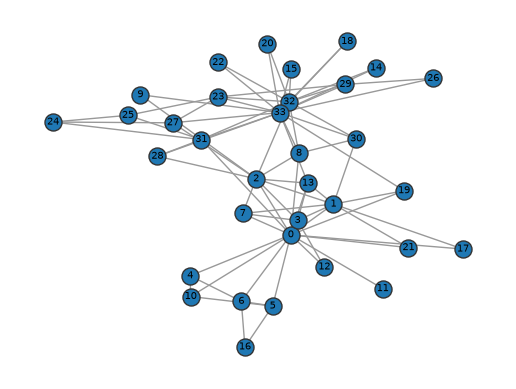

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
kcg = nx.karate_club_graph()
print(kcg.__class__)
betweenness_centrality = {}
for node_i in kcg.nodes():
    betweenness_centrality[node_i] = betweenness_centrality_from_scratch(kcg, node_i)
betweenness_centrality = (sorted(betweenness_centrality.items(), key=lambda x: x[1], reverse=True))
print("My Version: ")
print(betweenness_centrality)
print("Networkx Version: ")
betweenness_centrality_official = (sorted(nx.betweenness_centrality(kcg,).items(), key=lambda x: x[1], reverse=True))
print(betweenness_centrality_official)

pos = nx.spring_layout(kcg)
plt.plot()
nx.draw(kcg, pos, node_size=150, edgecolors='.2',
        with_labels=True, font_size='x-small', edge_color='.6')

**(b) Augment your function with error handling. It should be able to return useful**
**messages when given any of the following:**
* i. A node that is not in the graph
* ii. A graph that is not a networkx object
* iii. A graph with no connectivity (or not enough connectivity to produce a valid centrality result)
* iv. Any situation that might produce numerical difficulties (e.g. dividing by zero) for your chosen centrality measure

In [19]:
def betweenness_centrality_from_scratch(G, node_i):
    """
    Calculate the betweenness centrality for each node in a graph from scratch.

    Betweenness centrality is a measure of the extent to which a node lies on the shortest
    paths between other nodes in the network. This function computes the betweenness
    centrality for all nodes in the graph `G`.

    Parameters
    ----------
    G : networkx.Graph
        The input graph on which the betweenness centrality is calculated. It can
        be any type of graph (undirected, directed, etc.) supported by NetworkX.

    node_i : networkx.Node
        The input node on which the betweenness centrality is calculated.

    Returns
    -------
    centrality : float
        A float where the value is the corresponding betweenness centrality score as a function of the total number of nodes N, the total number of geodesics for all pairs of nodes in  graph G, and the number of geodesics node_i is part of in said graph, G.


    Time Complexity
    ---------------
    The overall time complexity is O(N^2) where N is the number of nodes, due to the use of
    combinations(G.nodes(), 2) dominating, which provides all "N choose 2" pairs of nodes.

    Notes
    -----
    If unweighted, networkx's all_shortest_paths() uses Breadth-First Search which is O(N), if weighted though, nx.all_shortest_paths() defaults to
    Dijkstra's which is O(E*N*log(N)), and if negative weights exist then it is O(N*E) due to Bellman-Ford. All where N is the number of nodes, where E is
    the number of edges.
    https://networkx.org/documentation/stable/_modules/networkx/algorithms/shortest_paths/unweighted.html

    Citations
    ---------
    Freeman, Linton C. “A Set of Measures of Centrality Based on Betweenness.” Sociometry, vol. 40, no. 1, 1977, pp. 35–41. JSTOR, https://doi.org/10.2307/3033543. Accessed 6 Oct. 2026.

    Example
    -------
    >>> import networkx as nx
    >>> G = nx.karate_club_graph()
    >>> node_i = 3
    >>> betweenness_centrality_from_scratch(kcg, node_i)
    (3, 0.011909271284271286)
    """
    import networkx as nx
    from itertools import combinations
    import logging

    #Error Handling Section
    #Check that G is a valid graph
    if not isinstance(G,nx.Graph):
        raise  ValueError("Graph provided is not a networkx graph!")
    #Node not a part of graph
    if node_i not in G.nodes():
        raise  ValueError("Node provided is not in graph!")
    # Not enough edges
    if G.number_of_edges() < 1:
        raise  ValueError("Graph provided has no connectivity!")

    #Catch any errors raised before we start:
    try:
        centrality = 0.0
        N = G.number_of_nodes()  # Total number of nodes in the graph
    except ValueError:
        logging.debug('Value Error: Invalid Input')
    except Exception as e:
            print(e)
            logging.debug('other error')

    '''
    Grabbing C_B(p_k) => C_B(node_i) = "the overall partial betweenness of point p_k."
    If there is only 1 geodesic (i.e., shortest path) C_B(p_k) is increased by 1.
    Otherwise, C_B(p_k) is increased relative to the proportion of geodesics p_k is apart of
    '''
    for a, b in combinations(G.nodes(), 2):              #For all "n choose 2" pairs of nodes...
        if node_i in (a, b): #Excluding cases where node_i is one of those nodes.
            continue
        try:
            paths = list(nx.all_shortest_paths(G, a, b)) #... compute all possible shortest paths from this pair
        except nx.NetworkXNoPath:
            continue
        except Exception as e:
            print(e)
            logging.debug('other error')

        g_ab = len(paths)                                #The total number of geodesics
        g_ab_i = 0                                       #The number of geodesics with node_i in them

        for p in paths: #For all geodesics (shortest paths)...
            if node_i in p:#...if node_i is in a geodesic...
                g_ab_i += 1 #... count it!
        if(g_ab_i==0):
            raise ValueError('Value Error: node_i not on any geodesics!')
        try:
            centrality += g_ab_i / g_ab #C_B(node_i), the sum, of the proportion of geodesics node_i is a part of, for all "n choose 2" combinations
        except ValueError:
            logging.debug('Value Error: Invalid Input')
        except Exception as e:
                print(e)
                logging.debug('other error')

    max_centrality = ((N**2)-(3*N)+2)/2 # max possible betweenness centrality
    centrality = centrality/max_centrality # betweeness centrality of node_i relative to the max possible betweeness centrality of 'G'
    return centrality

(c) Compare your function to the corresponding networkx function across several
graphs you design as test inputs, including one with no connectivity. Does your
function ever return different results from the networkx function? Why do you
think this is the case?

_In my first attempt, my version only aligned relatively speaking, where I produced slightly different values and orders than then one in networkX. E.g., I calculated node 2 to be the 2nd most central while networkx did so for node 33. Now however, I have it fixed and I believe it aligns fully!_

_Originally I didn't think of cases where there may be multiple equally valid shortest paths between 2 nodes, where node_i is only on a portion of said valid list of shortest paths._

(d) Putting it all together: Write a function that takes a centrality function as input
and tests the function for robustness to edge cases (like a graph with no connectivity) and correctness of outputs. Explain why you selected the test cases you
chose.

In [8]:
import networkx as nx
import numpy as np
kcg = nx.karate_club_graph()
node_i = 3
print(kcg.__class__)
betweenness_centrality = {}


#Check valid graph
betweenness_centrality_from_scratch(1, node_i)
#Check valid node
betweenness_centrality_from_scratch(kcg, 50)


G = nx.Graph()
G.add_nodes_from(reversed(range(10)))
print(list(G.subgraph([1,2,3])))

#Check valid connectivity
node_i=1
betweenness_centrality_from_scratch(G.subgraph([1]), node_i)


<class 'networkx.classes.graph.Graph'>


ValueError: Graph provided is not a networkx graph!

I picked 3 kinds of test cases and therefore errors to handle with my code. I focused in on input based errors: namely the Graph not being a valid nx.Graph() object, the Graph being valid but enough data to perform the centrality measure, and the node of interest not being a part of the graph, or alternatively not being within any of the shortest paths. I did these 3 cases as I figured this is where the bulk of the edge cases may lie, and as a back up, in case an exception I did not think of shows up, I attempt to catch for exceptions writ-large. This helps give more aid to the user of my function such that it is easier to use and debug code that leverages it. It also ensures a level of robustness and reliability via the back-up general exception.

#### Question 4 (20 points).


Download a network dataset from https://networkrepository.com/ with between
1, 000 < N < 20, 000 nodes, and explore it as described below.

I am using the following dataset on Facebook Artist Pages:
      Rossi, R., & Ahmed, N. (2015). The Network Data Repository with Interactive Graph Analytics and Visualization. Proceedings of the AAAI Conference on Artificial Intelligence, 29(1). https://doi.org/10.1609/aaai.v29i1.9277

In [9]:
import networkx as nx

friendships =nx.read_edgelist("data/soc-hamsterster/soc-hamsterster.edges",delimiter=" ")

(a) In 2-5 sentences, describe your network. What are the nodes, what are the links,
what domain is it from? Be sure to include appropriate citation(s) to the original
dataset or research paper, if relevant.

My network consists of friendships from the hamsterster website (Rossi, R., & Ahmed, N. (2015). The Network Data Repository with Interactive Graph Analytics and Visualization. Proceedings of the AAAI Conference on Artificial Intelligence, 29(1). https://doi.org/10.1609/aaai.v29i1.9277). According to the documentation found at https://networkrepository.com/soc-hamsterster.php, the network reflects friendships and family links between users on the website. Where each node is a user, and each edge a frienship.

(b) Compare your network’s properties to those of a randomized network, by selecting a network null model to compare against. Your null model should preserve
the degree distribution of the network, so randomize your network using e.g. a
configuration model or degree-preserving network rewiring (see Class 4).
* i. Create a figure with three subplots, corresponding to three distributions of your network; write brief interpretations of what you observe. These can be distributions of node properties (i.e. degree, centrality measures, etc.) or edge properties (i.e. edge weights). Be sure to bin these distributions appropriately.
* ii. Create an analogous figure for the randomized version of your network; write brief interpretations of what you observe.

In [11]:
import networkx as nx
import numpy as np
N = friendships.number_of_nodes()
L = friendships.number_of_edges()
print("N: ", N)
print("L: ", L)

N:  2426
L:  16630


In [12]:
deg = dict(friendships.degree())
avg_deg = np.mean(list(deg.values()))
print("avg_deg: ", avg_deg)

avg_deg:  13.709810387469085


In [13]:
closeness_centrality = nx.closeness_centrality(friendships)

In [14]:
C_i = nx.clustering(friendships)
avg_C_i = np.mean(list(C_i.values()))
print("Average C_i: ", avg_C_i)

Average C_i:  0.5375333362074076


In [15]:
def configuration_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the configuration model from a given degree sequence
    without using the NetworkX built-in function.

    The configuration model generates a random graph that preserves the degree
    sequence of nodes by assigning "stubs" or "half-edges" to each node and
    randomly pairing these stubs to form edges. This process can result in
    graphs with self-loops and parallel edges, which can be removed if needed.

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of
        the degrees in this sequence must be even for the configuration model
        to create a valid graph.

    Returns
    -------
    G : networkx.MultiGraph
        A multigraph generated from the given degree sequence. The graph may
        contain self-loops and parallel edges, which are allowed in the
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on
      their degree and then randomly pairing them to form edges. The resulting
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction.
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(E), where E is the number of edges in the graph.

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """

    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    # Create stubs list: node i appears degree_sequence[i] times
    stubs = []
    for node, degree in enumerate(degree_sequence):
        stubs.extend([node] * degree)

    # Shuffle stubs to randomize the pairing process
    np.random.shuffle(stubs)

    # Initialize an empty multigraph
    G = nx.MultiGraph()

    # Add nodes to the graph
    G.add_nodes_from(range(len(degree_sequence)))

    # Pair stubs to create edges
    while stubs:
        u = stubs.pop()
        v = stubs.pop()

        # Add the edge to the graph
        G.add_edge(u, v)

    if return_simple:
        # Convert the multigraph to a simple graph (remove parallel edges and self-loops)
        G_simple = nx.Graph(G)  # This removes parallel edges and self-loops by default

        return G_simple

    else:
        return G

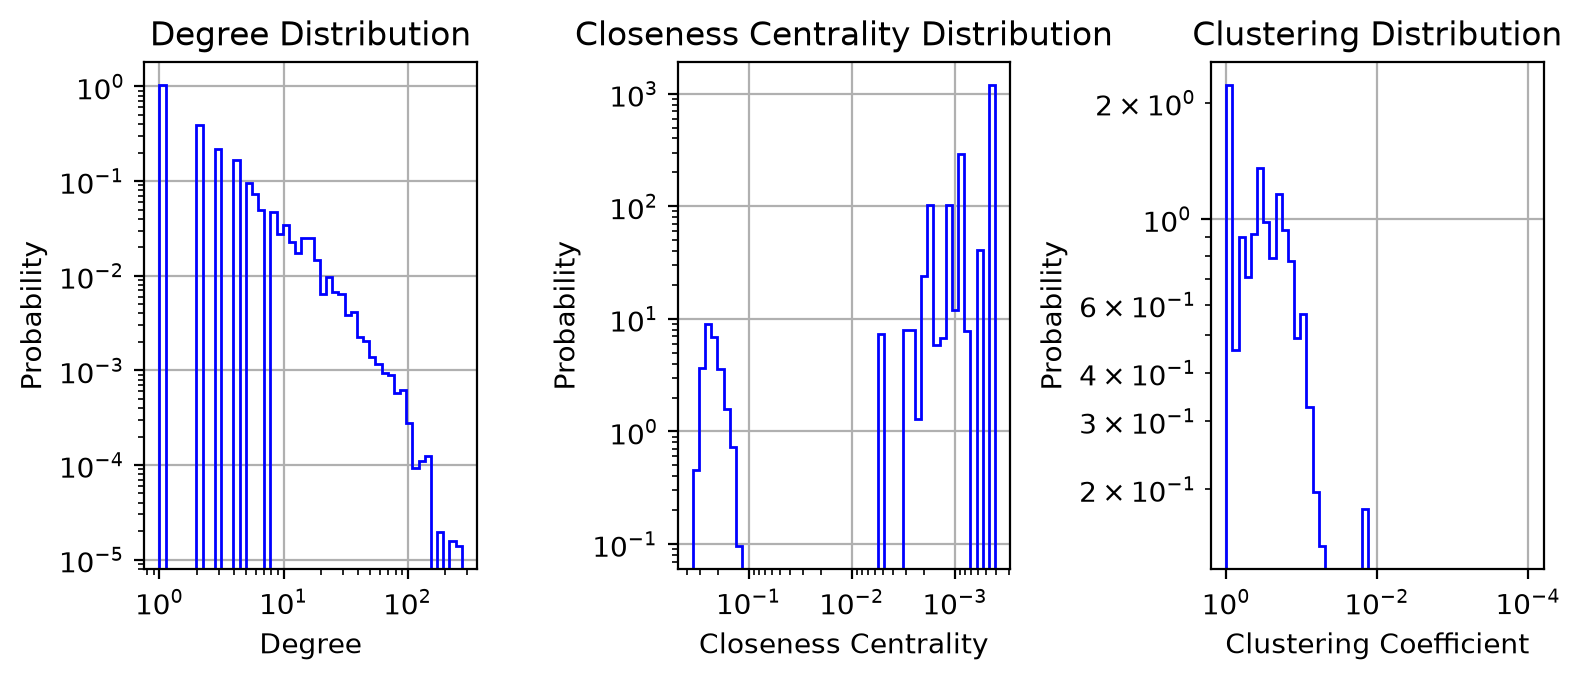

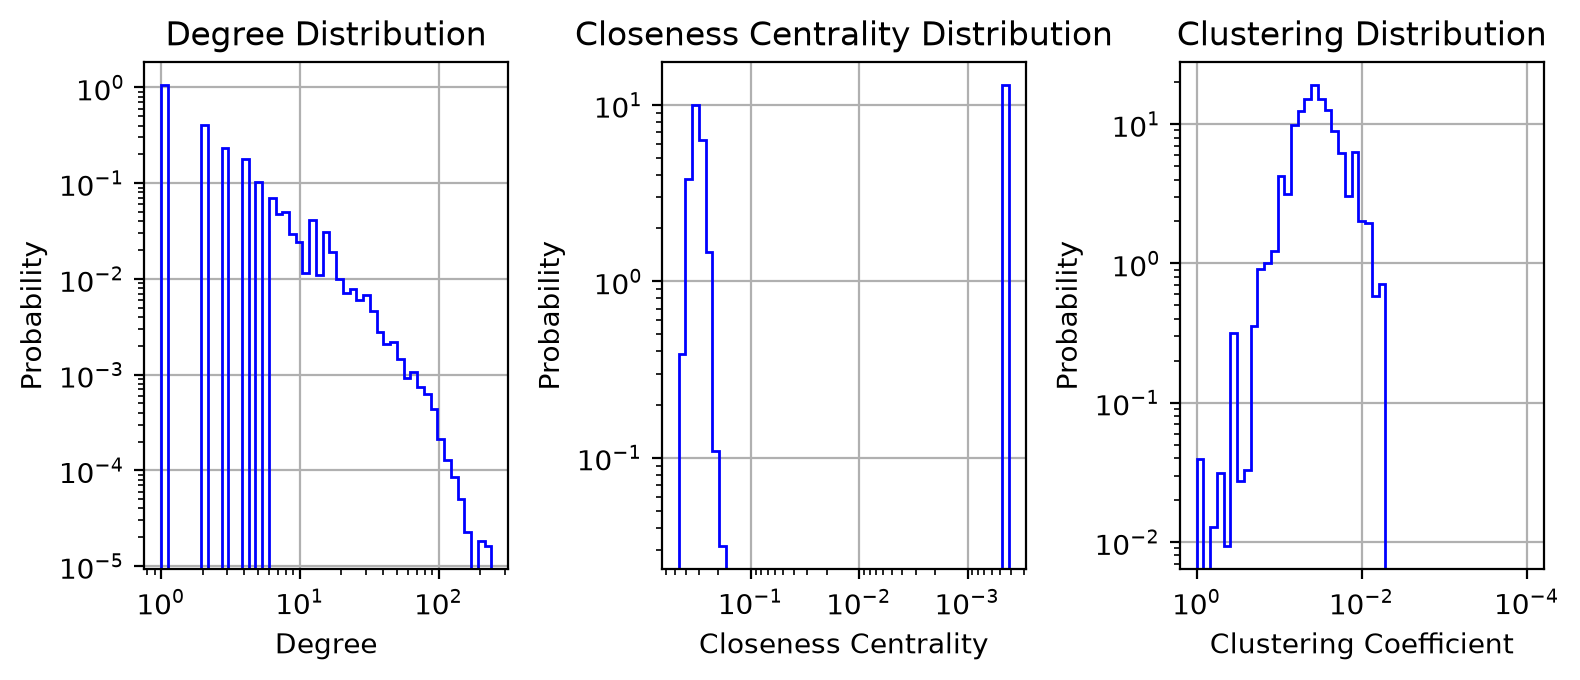

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,3,figsize=(8,3.5),dpi=200)

deg_bins = np.geomspace(np.min(list(deg.values())),np.max(list(deg.values())))
ax[0].hist(list(deg.values()),bins=deg_bins, density=True,color = 'b',histtype='step')
ax[0].loglog()
ax[0].set_title("Degree Distribution")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Probability")
ax[0].grid(True)

cen_bins = np.geomspace(np.min(list(closeness_centrality.values())),np.max(list(closeness_centrality.values())))
ax[1].hist(list(closeness_centrality.values()),bins=cen_bins,density=True,color = 'b',histtype='step')
ax[1].loglog()
ax[1].set_title("Closeness Centrality Distribution")
ax[1].set_xlabel("Closeness Centrality")
ax[1].set_ylabel("Probability")
ax[1].xaxis.set_inverted(True)
ax[1].grid(True)

clu_bins = np.geomspace(np.min(list(C_i.values()))+1e-4,np.max(list(C_i.values())))
ax[2].hist(list(C_i.values()),bins=clu_bins,density=True,color = 'b',histtype='step')
ax[2].loglog()
ax[2].set_title("Clustering Distribution")
ax[2].set_xlabel("Clustering Coefficient")
ax[2].set_ylabel("Probability")
ax[2].xaxis.set_inverted(True)
ax[2].grid(True)

fig.tight_layout()
plt.show()
#---Configuration Model Version
my_null_model = configuration_model_from_degree_sequence(list(deg.values()),return_simple=True)
deg2 = dict(my_null_model.degree())
closeness_centrality2 = nx.closeness_centrality(my_null_model)
C_i2 = nx.clustering(my_null_model)

fig2, ax2 = plt.subplots(1,3,figsize=(8,3.5),dpi=200)
deg_bins2 = np.geomspace(np.min(list(deg2.values())),np.max(list(deg2.values())))
ax2[0].hist(list(deg2.values()),bins=deg_bins2, density=True,color = 'b',histtype='step')
ax2[0].loglog()
ax2[0].set_title("Degree Distribution")
ax2[0].set_xlabel("Degree")
ax2[0].set_ylabel("Probability")
ax2[0].grid(True)

cen_bins2 = np.geomspace(np.min(list(closeness_centrality2.values())),np.max(list(closeness_centrality2.values())))
ax2[1].hist(list(closeness_centrality2.values()),bins=cen_bins2,density=True,color = 'b',histtype='step')
ax2[1].loglog()
ax2[1].set_title("Closeness Centrality Distribution")
ax2[1].set_xlabel("Closeness Centrality")
ax2[1].set_ylabel("Probability")
ax2[1].xaxis.set_inverted(True)
ax2[1].grid(True)

clu_bins2 = np.geomspace(np.min(list(C_i2.values()))+1e-4,np.max(list(C_i2.values())))
ax2[2].hist(list(C_i2.values()),bins=clu_bins2,density=True,color = 'b',histtype='step')
ax2[2].loglog()
ax2[2].set_title("Clustering Distribution")
ax2[2].set_xlabel("Clustering Coefficient")
ax2[2].set_ylabel("Probability")
ax2[2].xaxis.set_inverted(True)
ax2[2].grid(True)
fig2.tight_layout()
plt.show()

In my original dataset of friendships we can see the degree distribution appears to follow a truncated power-law, with low-degree nodes occurring commonly and high degree nodes occurring less and less commonly as degree increases. Meanwhile, my closeness centrality appears to fall into 2 buckets: very close or not very close, with both being on the same order of magnitude in terms of probability to occur. Lastly, my clustering coefficient is commonly high across all nodes, with a steep drop off in probability of occurrence as soon as the clustering coefficient begins to dip below 0.01.

In my configuration null model, we can see all these trends maintain present albeit with some marginal differences. Namely, some of the degree distribution between 10 and 100 appears slightly less probable in the configuration model, and similarly high closeness centrality is a little less probable than low closeness centrality (_relative to the original dataset_). Lastly, the clustering coefficient becomes most common at a slightly lower value than the original dataset. This may indicate that the original dataset was perhaps tighter knit relative to the configuration model version, and thereby experienced slightly higher degree, closeness and clustering as a result.

(c) Discuss the similarities and/or differences between your network dataset and the
randomized versions of this network. How does this exercise—comparing network
data to a null model—help us gain insights from network analysis?

The general trends in the datasets remained consistent: the degree distribution resembling a truncated power law, the closeness centrality falling into high and low buckets, and the clustering being generally high. The main differences arose in the extent to which these trends appeared, with the configuration model (i.e., randomized) version, experiencing slightly lower probabilities for high centrality, high clustering and high degreee (_relatively speaking_).

Overall this exercise helps us gain insights into from networks analysis, as it allows us to characterize how this network may be different or unique from what is expected at random (_even if it's only a marginal that difference may be present_). It also allows us to speculate and hypothesize how a network may be different, when we notice a theme of marginal differences across different measures.

#### (Optional) Question 5 (5 bonus points).


For every problem set this semester, there will be an opportunity to earn extra credit.
Since this is a fairly new course (of a new masters program), we are eager to receive
genuine feedback on the material, pace, instruction style, etc. of the course so far.
Note: Learning how to give effective feedback is an important skill during your PhD,
so we hope this is an opportunity for you to skill-build and improve the course for
future students. (Also, it’s a bit odd to be evaluated on on how good your feedback
is, so we will be generous with awarding points for these. With that said, please take
some time to provide us with productive comments!) If you need resources for giving
effective feedback, here are a few:
* https://hbr.org/2017/10/how-to-give-feedback-people-can-actually-use
* https://www.sessionlab.com/blog/feedback-techniques/

I'm honestly really enjoying the course so far! I'm learning a lot and I especially appreciate the in-class coding exercises we have been doing lately. Despite working in data science, I've never been the strongest coder, so I tend to take a fair amount of time to think and get through problems, but it's because of that, that I think I feel that much more confident in the material in the practice of it all. I think in that sense the pro-active nature of the course has been a strong asset, in that it was good there was the foresight to see that adding in exercises could be worthwhile! I think similarly the capacity there has been to allow lectures to speed-up or slow-down, ask questions, and go on tangents and really explore and play with the material has added a lot of value and is very appreciated! I can see a lot of students joining and taking this course to study a specific kind of network, or coming in with a different background and wanting or needing to know more about some topics over others.

I'm afraid I don't have too much constructive criticism for the course at the moment. I think if I had to name some it would be, that I've noticed that the students outside of my NetSci courses (_right now I'm taking 1 other class called Big Data for Cities that has a lot of MPP and Structural Engineering kinds of students_) tended to have little to no background in coding, so I could see in the future once we get more students, we may see students with less background struggling. That all being said, I also realize that at the moment we are a small cohort and as such there isn't really a huge needed to go slow like that. In any case, I mention it just as something to be cognizant of in case it's something the course encounters in the future.

Other than that, and this is perhaps nitpick territory, but it could be valuable to have any windows specific coding errors mentioned perhaps as like a little 'heads-up' in some of the code, but it honestly hasn't really been a problem at all in my experience. I think I had 1 error in reading a file due to Windows but I was able to just tell Python to ignore it as an argument to the read() and then it worked fine.

Hope this feedback is of help, and looking forward to the rest of the course!
